# День 3 — attention-матрицы

Модель `distilbert-base-uncased`: 6 слоёв и 12 голов внимания. Форма одной матрицы — `[seq_len, seq_len]`: строка это query, столбец это key.

Карты сохраняются в `outputs/attention/`.

## Задача 1. Загрузка модели с attention

In [1]:
import sys
from pathlib import Path

import torch
from transformers import AutoModel

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.attention import load_attention_model, visualize_attention
from src.tokenization import MODEL_NAME, load_tokenizer

%matplotlib inline

tokenizer = load_tokenizer(MODEL_NAME)
model = load_attention_model(MODEL_NAME)
print(AutoModel.__name__, model.name_or_path)
print(f"output_attentions: {model.config.output_attentions}")
print(f"слоёв: {model.config.n_layers}, голов: {model.config.num_attention_heads}")
print(f"training: {model.training}")

text = "The amazing movie won many awards"
tokens = tokenizer(text, return_tensors="pt")

Matplotlib is building the font cache; this may take a moment.


W1023 17:55:48.888000 40275 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


AutoModel distilbert-base-uncased
output_attentions: True
слоёв: 6, голов: 12
training: False


## Задача 2. Attention-веса

In [2]:
with torch.no_grad():
    outputs = model(**tokens)

print(type(outputs.attentions))
print(f"Количество слоёв: {len(outputs.attentions)}")
print(f"Форма attention для слоя 0: {outputs.attentions[0].shape}")

attention = outputs.attentions[0]
print(f"Attention shape: {attention.shape}")

attn_single = attention[0, 0]
print(f"Single head shape: {attn_single.shape}")

<class 'tuple'>
Количество слоёв: 6
Форма attention для слоя 0: torch.Size([1, 12, 8, 8])
Attention shape: torch.Size([1, 12, 8, 8])
Single head shape: torch.Size([8, 8])


## Задача 3. Визуализация одной головы

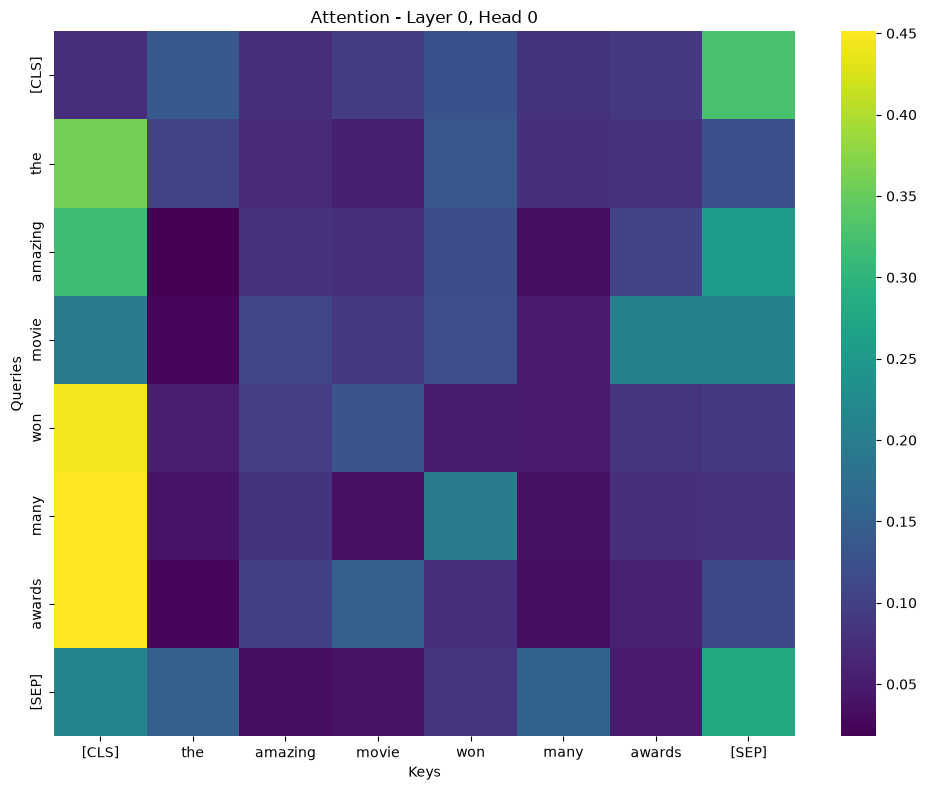

/Users/vladimir.fedorov/fourth_task_transformers/outputs/attention/attention_layer0_head0.png


In [3]:
path = visualize_attention(tokens, outputs.attentions, tokenizer, layer=0, head=0)
print(path)

## Задача 4. Разные слои

Первый слой, средний и последний. На последних слоях внимание обычно уже, чем на первом.

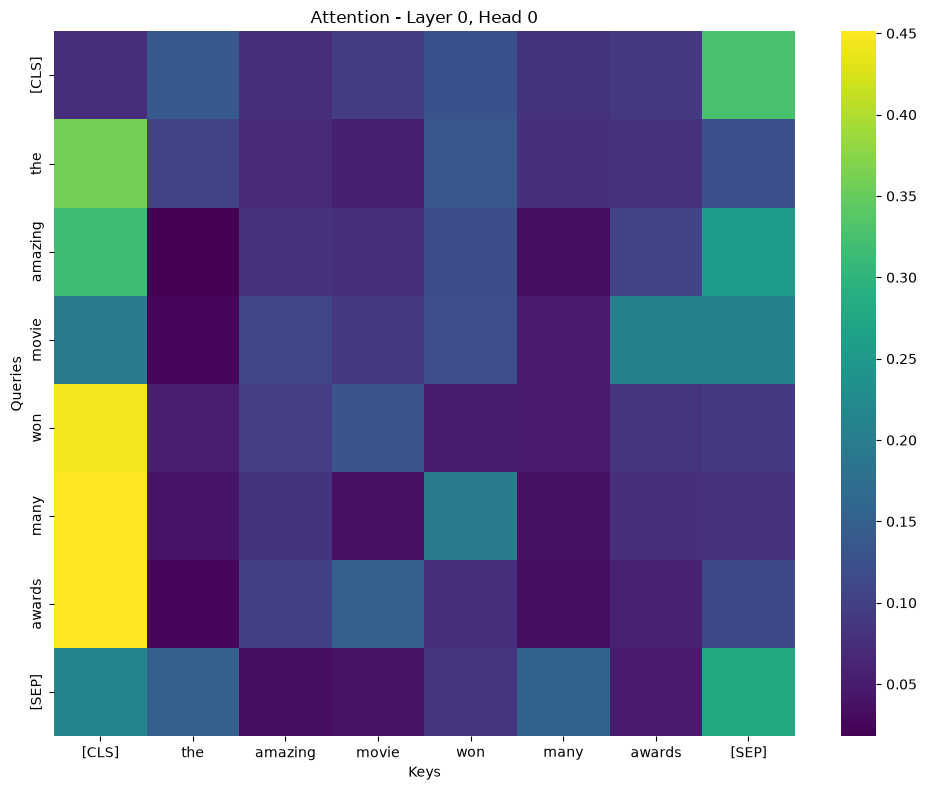

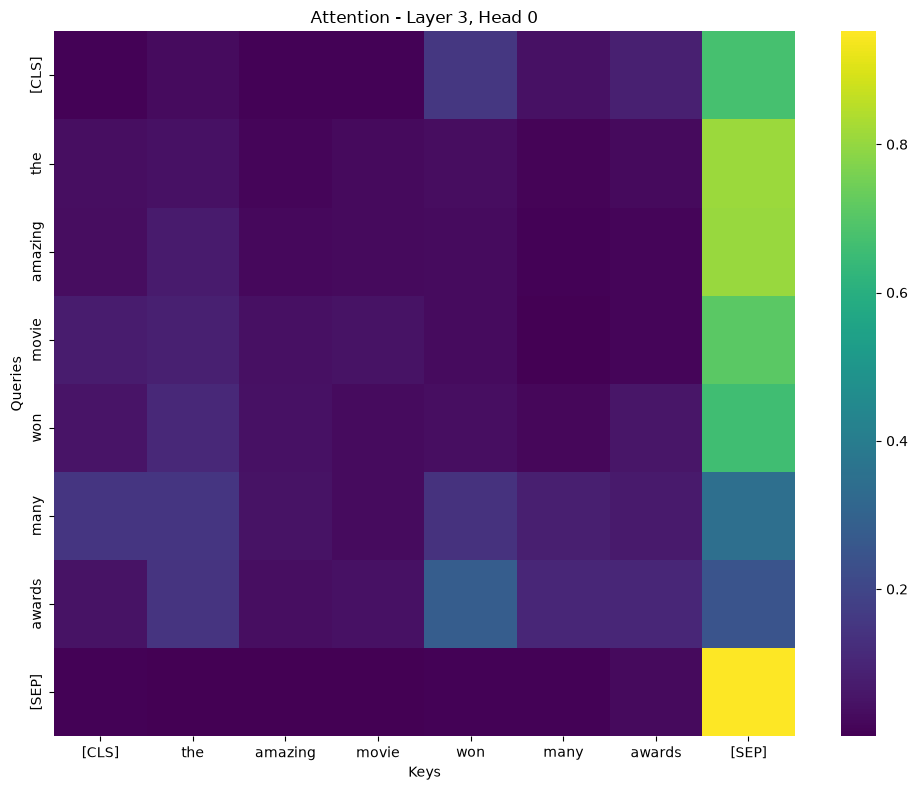

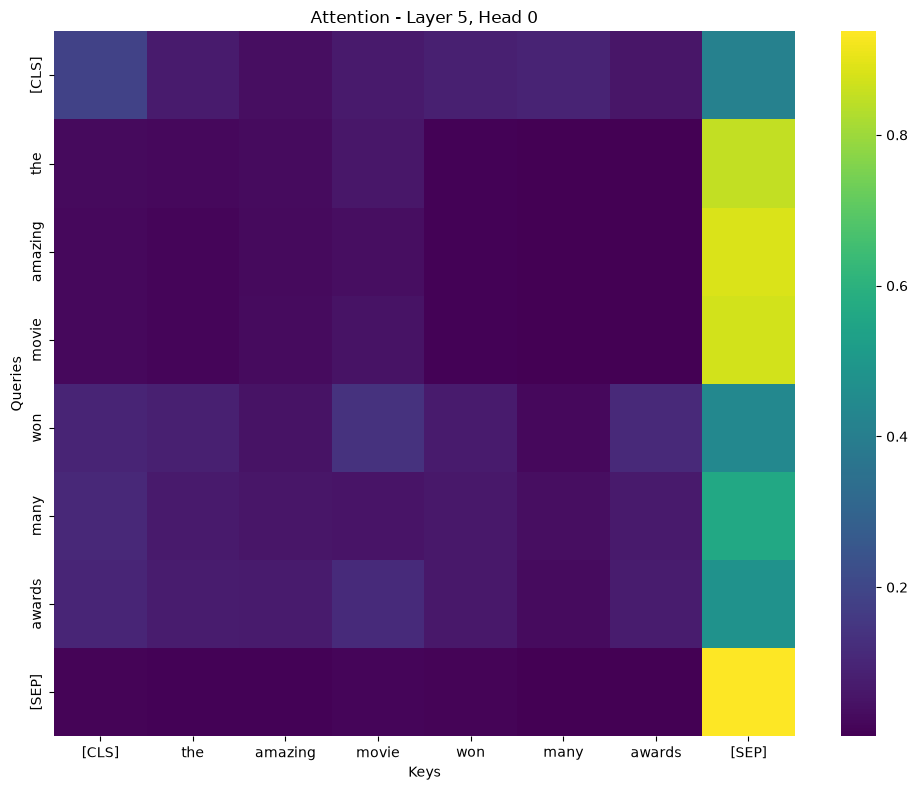

In [4]:
for layer in (0, 3, 5):
    visualize_attention(tokens, outputs.attentions, tokenizer, layer=layer, head=0)

## Задача 5. Все головы слоя 0

У `distilbert-base-uncased` 12 голов. Каждая смотрит на свои связи между токенами.

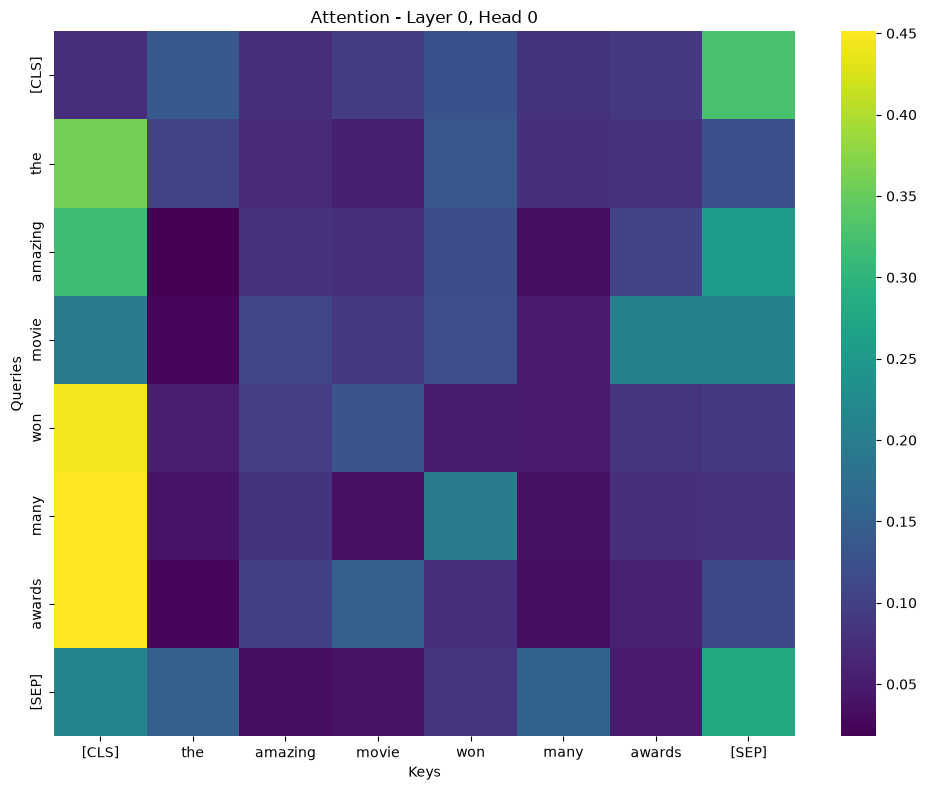

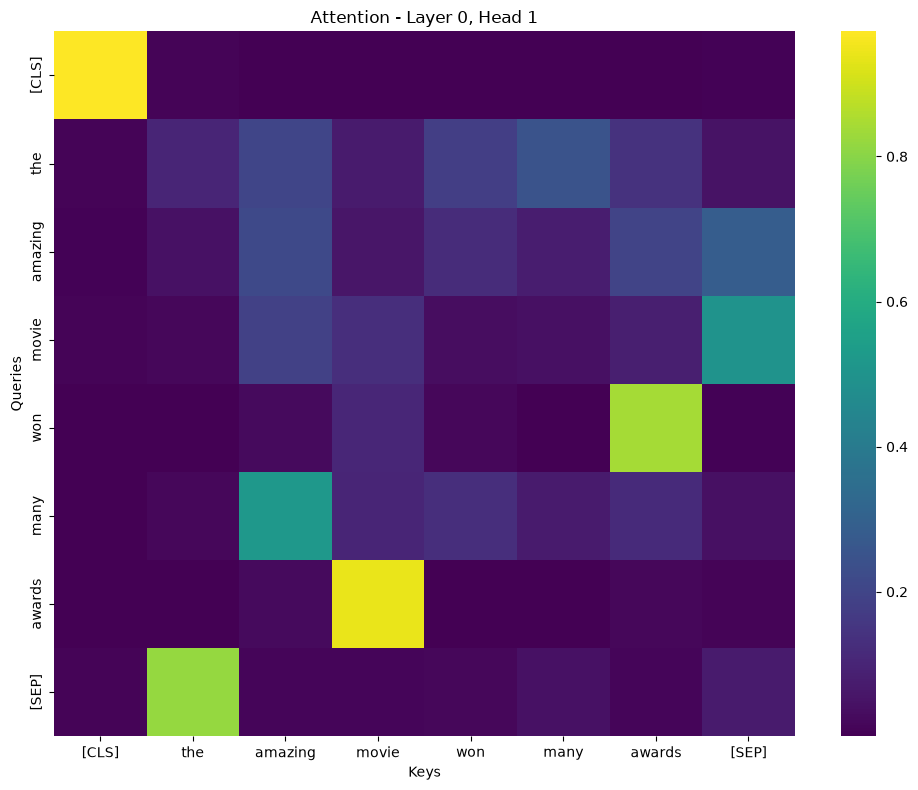

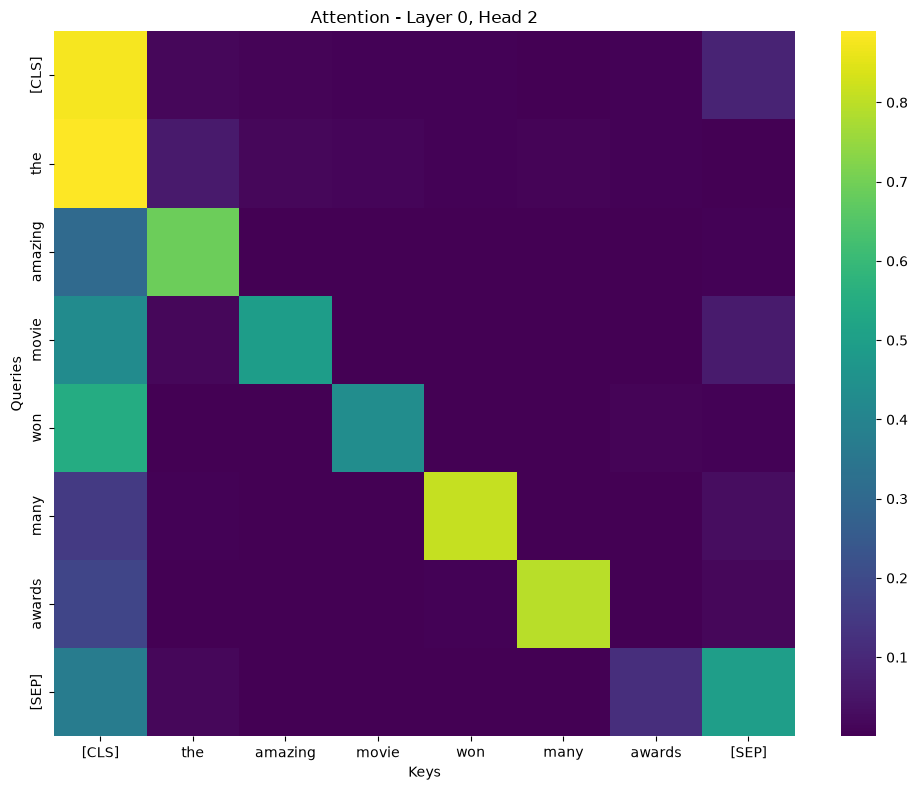

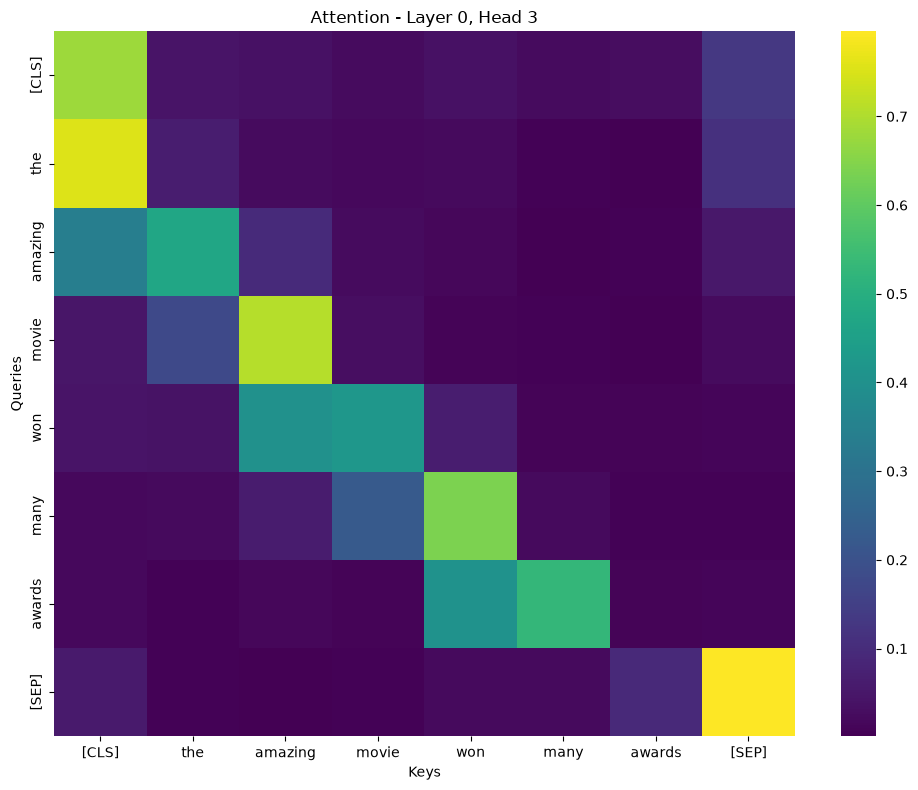

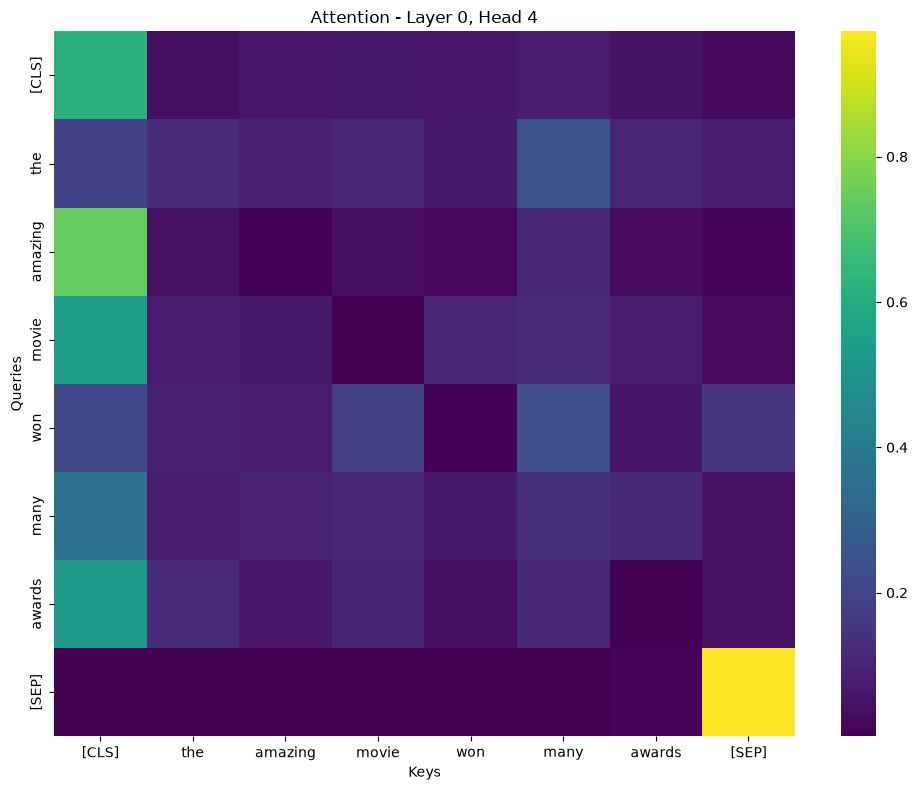

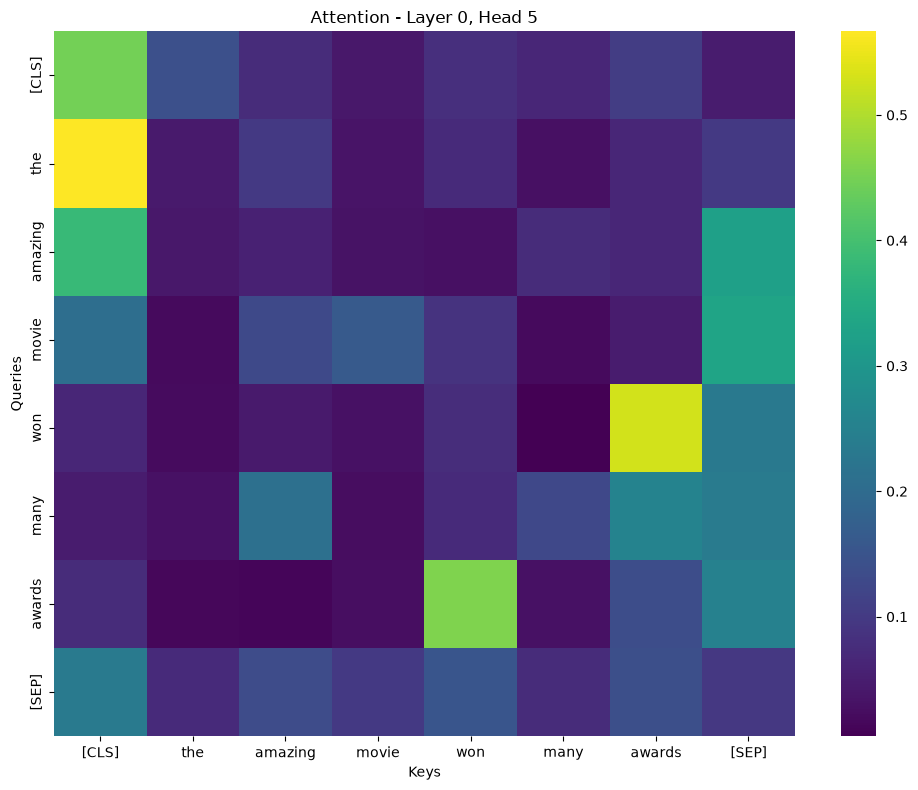

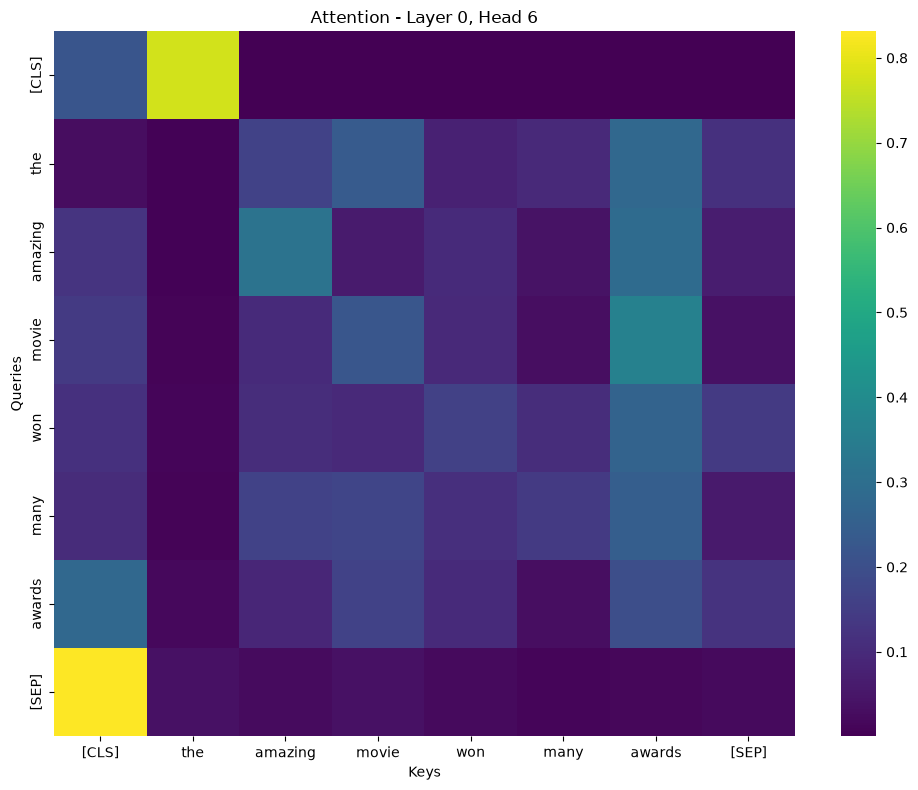

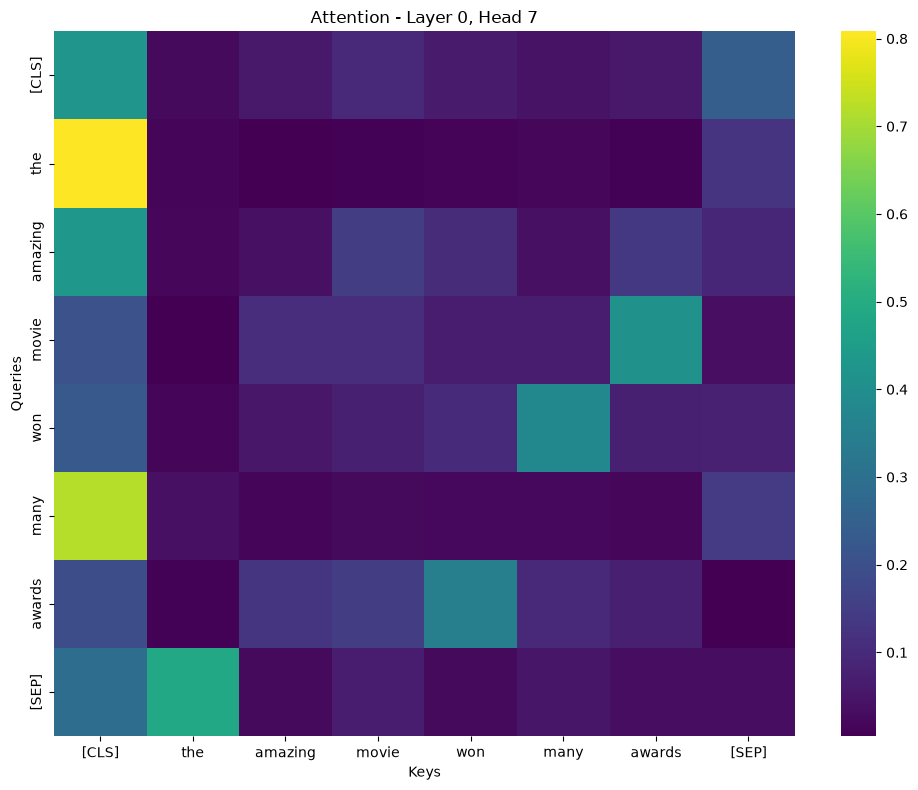

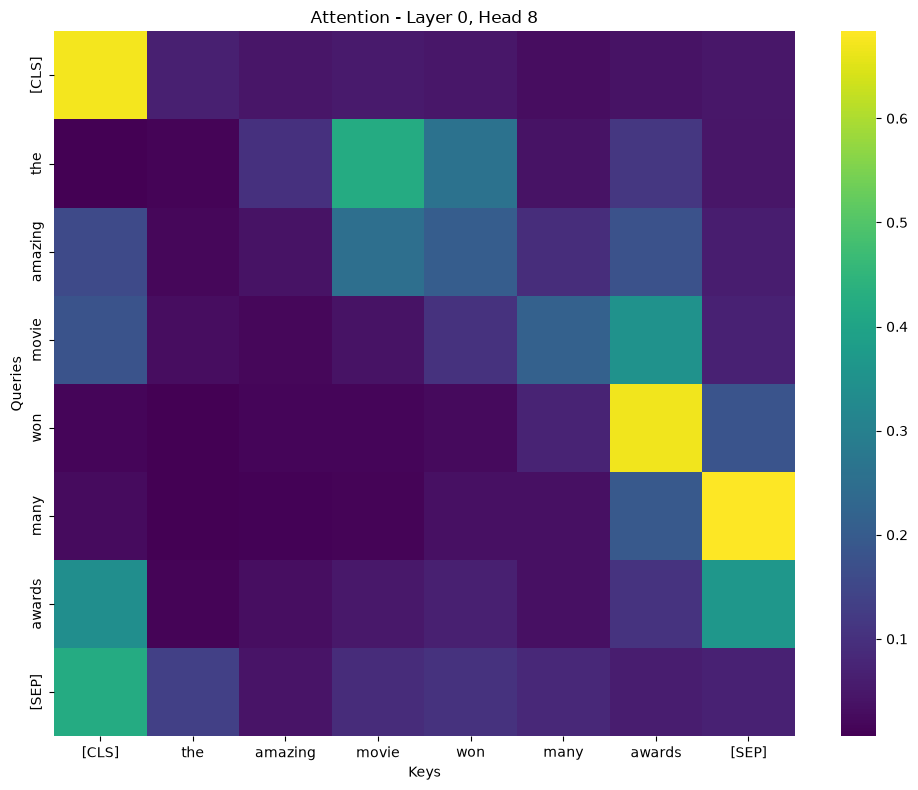

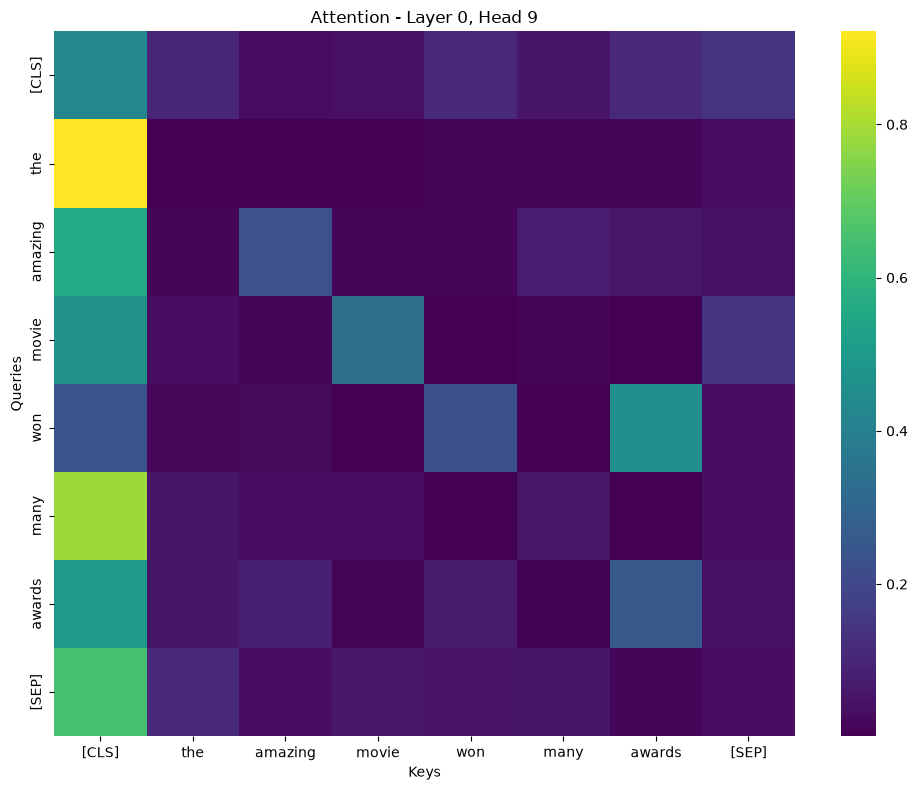

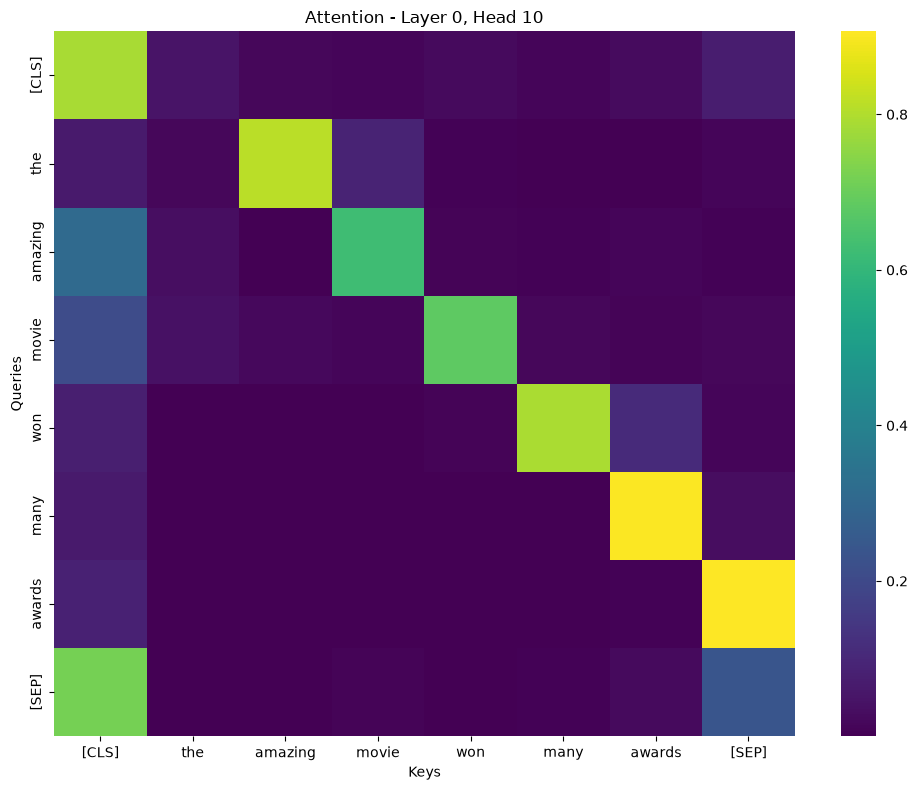

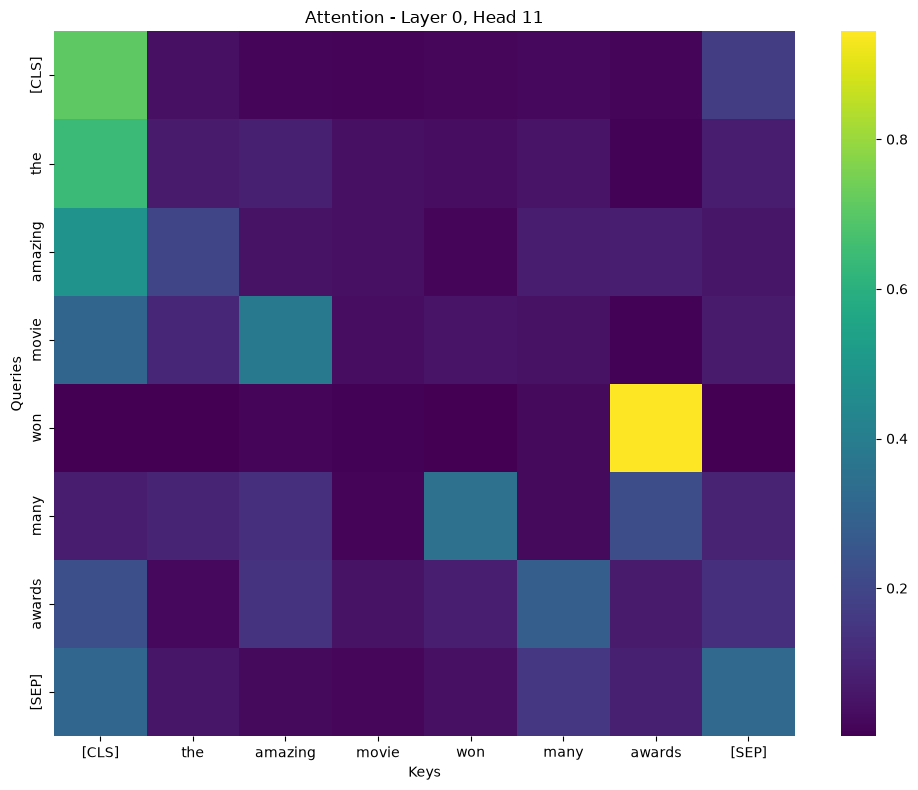

In [5]:
for head in range(model.config.num_attention_heads):
    visualize_attention(tokens, outputs.attentions, tokenizer, layer=0, head=head)

## Задача 6. Внимание к слову terrible

Карта пишется в отдельный файл, чтобы не затереть слой 5 из задачи 4.

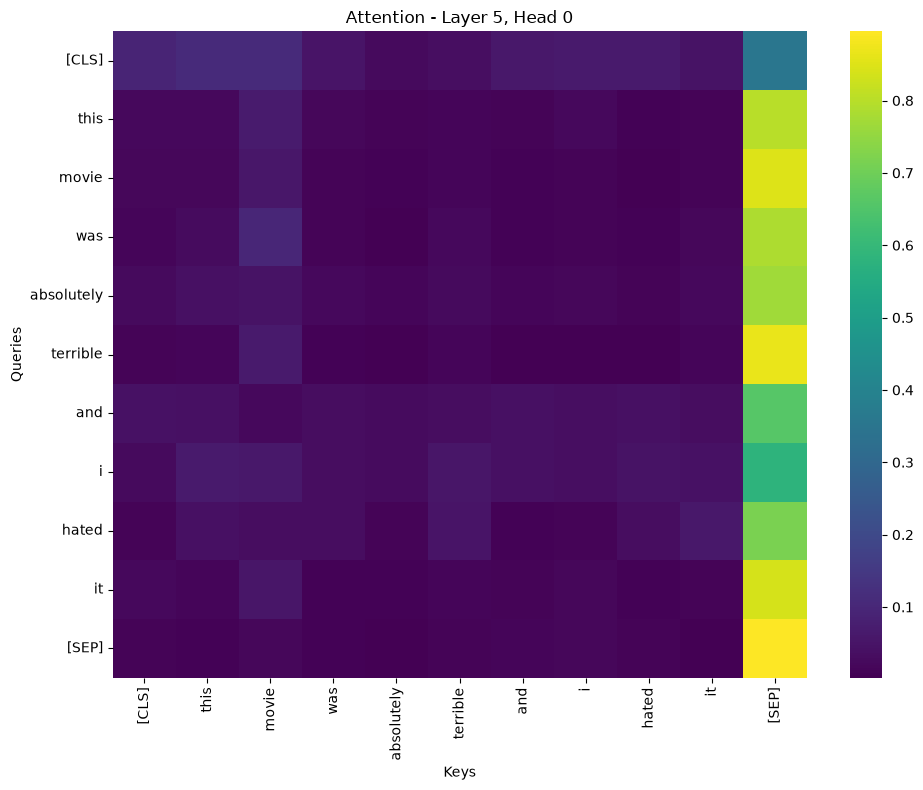

/Users/vladimir.fedorov/fourth_task_transformers/outputs/attention/attention_terrible_layer5_head0.png
terrible -> [SEP] (0.866)


In [6]:
text = "This movie was absolutely terrible and I hated it"
tokens = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model(**tokens)

path = visualize_attention(
    tokens,
    outputs.attentions,
    tokenizer,
    layer=5,
    head=0,
    filename="attention_terrible_layer5_head0.png",
)
print(path)

token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"][0])
idx = token_list.index("terrible")
row = outputs.attentions[5][0, 0, idx]
top = int(row.argmax())
print(f"terrible -> {token_list[top]} ({row[top].item():.3f})")